# Compare abundance z-scores from different assays

In [2]:
import polars as pl
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import seaborn as sns
import warnings
import sys
sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

sys.path.append("../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../../2_individual_assay_results")
from analyses_plot_utils import *
warnings.filterwarnings('ignore')

In [6]:
all_gene_variants = pl.read_csv(
    "../3_outputs/0_all_gene_variants_assayed_summary.tsv",
    separator="\t", infer_schema_length=100000
)
all_gene_variants

dual_img_union_df = all_gene_variants.filter(
    (pl.col("dualipa_score").is_not_null() | pl.col("imaging_score").is_not_null())
)
dual_img_intersect_df = all_gene_variants.filter(
    (pl.col("dualipa_score").is_not_null(),
    pl.col("imaging_score").is_not_null())
)

dual_img_intersect_df.shape

(308, 1037)

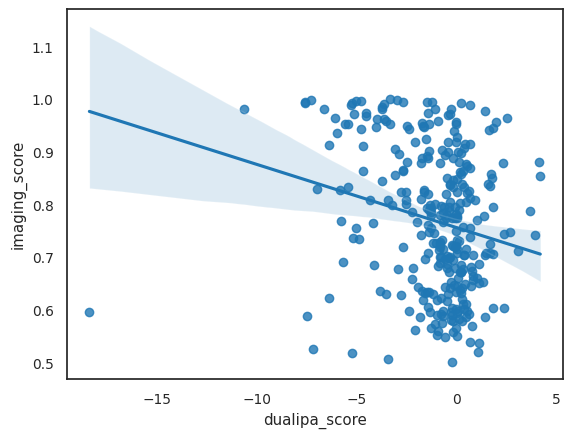

dualipa_score
f64
-0.218278


In [13]:
ax = sns.regplot(
    data=dual_img_intersect_df.to_pandas(),
    x="dualipa_score",
    y="imaging_score"
)
plt.show()
dual_img_intersect_df.select(pl.corr("dualipa_score", "imaging_score"))

In [15]:
dual_img_intersect_df

symbol,aa_change,gene_variant,spdi,nt_change,chr_num,nuc_loc,ref_allele,alt_allele,Chrom,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,ensembl_protein_id,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,entry_well_conso,entry_seq_pool,db_plate,db_well,n2h_plate,n2h_well,dualip_plate,dualip_well,mislocalization_plate,mislocalization_well,entry_sequenced,entry_sequence_confirmation_class,db_sequenced,db_sequence_confirmation_class,n2h_sequenced,n2h_sequence_confirmation_class,n2h_ref_sequence_confirmation_class,…,g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,dualipa_score,dualipa_abun_change,dualipa_abun_chg_dir,ppi_euclid_distance,ppi_num_edges,ppi_normalized_euclid_distance,ppi_score,seq,seq_aa,ppi_hit,img_U2OS_cc_t_stat,img_U2OS_cc_t_pval,img_U2OS_cc_t_adj_pval,img_U2OS_prot_abun_t_stat,img_U2OS_prot_abun_t_pval,img_U2OS_prot_abun_t_adj_pval,img_Metadata_Bio_Batch,imaging_score,img_misloc_score,img_pheno_hit,img_misloc_hit,img_pheno_hit_strict,dualipa_hit,imaging_hit
str,str,str,str,str,i64,i64,str,str,str,str,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,…,str,str,f64,f64,str,str,str,str,str,str,i64,str,bool,f64,str,str,f64,i64,f64,f64,str,str,bool,f64,f64,f64,f64,f64,f64,str,f64,f64,bool,bool,bool,bool,bool
"""AGXT""","""Ala248Ser""","""AGXT_Ala248Ser""","""NC_000002.12:240875170:G:T""","""742G>T""",2,240875170,"""G""","""T""","""2""","""ENSG00000172482""",70497,3857,"""CCSBVarC008212""","""ALE00008198""","""ENSP00000302620.3""","""Edgotyping3""","""VUSMutGDEh004""","""G07""","""GDEhDisVCh_40002""","""E09""","""2""","""VUSMutGDDh004""","""G07""","""VUSN2Hmut_GDN2h_01""","""F08""","""VUSMutpDEST2_14""","""A09""","""VUSmut_GDEh01""","""F08""",1.0,1.0,1.0,1.0,1.0,2.0,1.0,…,null,null,98.85,0.0,""">90""","""<10""","""259900""","""autosomal recessive""","""OMIM""","""Rare genetic eye disease; Rare…",3,"""HYPEROXALURIA, PRIMARY, TYPE I""",false,-0.456923,"""N""","""Decrease""",0.031478,1,0.031478,0.034037,"""ATGGCCTCTCACAAGCTGCTGGTGACCCCC…","""MASHKLLVTPPKALLKPLSIPNQLLLGPGP…",false,-0.333299,0.760844,0.809675,1.799485,0.169768,0.211059,"""2024_01_Batch_7-8""",0.703114,0.699193,false,false,false,false,false
"""AGXT""","""Ala248Val""","""AGXT_Ala248Val""","""NC_000002.12:240875171:C:T""","""743C>T""",2,240875171,"""C""","""T""","""2""","""ENSG00000172482""",70497,3858,"""CCSBVarC008213""","""ALE00008199""","""ENSP00000302620.3""","""Edgotyping3""","""VUSMutGDEh004""","""H07""","""GDEhDisVCh_40002""","""F09""","""2""","""VUSMutGDDh004""","""H07""","""VUSN2Hmut_GDN2h_01""","""G08""","""VUSMutpDEST2_14""","""B09""","""VUSmut_GDEh01""","""G08""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,…,null,null,98.85,0.0,""">90""","""<10""","""259900""","""autosomal recessive""","""OMIM""","""Rare genetic eye disease; Rare…",3,"""HYPEROXALURIA, PRIMARY, TYPE I""",false,-0.17962,"""N""","""Decrease""",0.108843,1,0.108843,0.117691,"""ATGGCCTCTCACAAGCTGCTGGTGACCCCC…","""MASHKLLVTPPKALLKPLSIPNQLLLGPGP…",false,-0.718623,0.495655,0.580086,-1.115418,0.301494,0.353962,"""2024_01_Batch_7-8""",0.55768,0.562741,false,false,false,false,false
"""AGXT""","""Ala295Thr""","""AGXT_Ala295Thr""","""NC_000002.12:240877573:G:A""","""883G>A""",2,240877573,"""G""","""A""","""2""","""ENSG00000172482""",70497,3874,"""CCSBVarC008224""","""ALE00008210""","""ENSP00000302620.3""","""Edgotyping3""","""VUSMutGDEh005""","""B06""","""GDEhDisVCh_40002""","""A11""","""2""","""VUSMutGDDh005""","""B06""","""VUSN2Hmut_GDN2h_02""","""C02""","""VUSMutpDEST2_14""","""E10""","""VUSmut_GDEh02""","""C02""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,…,null,null,98.89,2.8301888,""">90""","""<10""","""259900""","""autosomal recessive""","""OMIM""","""Rare genetic eye disease; Rare…",3,"""HYPEROXALURIA, PRIMARY, TYPE I""",false,-1.609773,"""Uncertain""","""Decrease""",0.490348

In [14]:
agxt_gene_info = dual_img_union_df.filter(
    pl.col("symbol")=="AGXT",
)
agxt_gene_info

symbol,aa_change,gene_variant,spdi,nt_change,chr_num,nuc_loc,ref_allele,alt_allele,Chrom,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,ensembl_protein_id,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,entry_well_conso,entry_seq_pool,db_plate,db_well,n2h_plate,n2h_well,dualip_plate,dualip_well,mislocalization_plate,mislocalization_well,entry_sequenced,entry_sequence_confirmation_class,db_sequenced,db_sequence_confirmation_class,n2h_sequenced,n2h_sequence_confirmation_class,n2h_ref_sequence_confirmation_class,…,g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,dualipa_score,dualipa_abun_change,dualipa_abun_chg_dir,ppi_euclid_distance,ppi_num_edges,ppi_normalized_euclid_distance,ppi_score,seq,seq_aa,ppi_hit,img_U2OS_cc_t_stat,img_U2OS_cc_t_pval,img_U2OS_cc_t_adj_pval,img_U2OS_prot_abun_t_stat,img_U2OS_prot_abun_t_pval,img_U2OS_prot_abun_t_adj_pval,img_Metadata_Bio_Batch,imaging_score,img_misloc_score,img_pheno_hit,img_misloc_hit,img_pheno_hit_strict,dualipa_hit,imaging_hit
str,str,str,str,str,i64,i64,str,str,str,str,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,…,str,str,f64,f64,str,str,str,str,str,str,i64,str,bool,f64,str,str,f64,i64,f64,f64,str,str,bool,f64,f64,f64,f64,f64,f64,str,f64,f64,bool,bool,bool,bool,bool
"""AGXT""","""Ala186Val""","""AGXT_Ala186Val""","""NC_000002.12:240873011:C:T""","""557C>T""",2,240873011,"""C""","""T""","""2""","""ENSG00000172482""",70497,3835,"""CCSBVarC008198""","""ALE00008184""","""ENSP00000302620.3""","""Edgotyping3""","""VUSMutGDEh004""","""C05""","""GDEhDisVCh_40002""","""C07""","""2""","""VUSMutGDDh004""","""C05""","""VUSN2Hmut_GDN2h_01""","""F07""","""VUSMutpDEST2_14""","""E06""","""VUSmut_GDEh01""","""F07""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,…,null,null,98.73,0.9433962,""">90""","""<10""","""259900""","""autosomal recessive""","""OMIM""","""Rare genetic eye disease; Rare…",3,"""HYPEROXALURIA, PRIMARY, TYPE I""",false,null,null,null,0.149468,1,0.149468,0.161619,"""ATGGCCTCTCACAAGCTGCTGGTGACCCCC…","""MASHKLLVTPPKALLKPLSIPNQLLLGPGP…",false,-2.928613,0.022068,0.04865,-4.020407,0.005057,0.009488,"""2024_01_Batch_7-8""",0.728047,0.69137,false,false,false,false,false
"""AGXT""","""Ala210Pro""","""AGXT_Ala210Pro""","""NC_000002.12:240874010:G:C""","""628G>C""",2,240874010,"""G""","""C""","""2""","""ENSG00000172482""",70497,3848,"""CCSBVarC008207""","""ALE00008193""","""ENSP00000302620.3""","""Edgotyping3""","""VUSMutGDEh004""","""F06""","""GDEhDisVCh_40002""","""E08""","""2""","""VUSMutGDDh004""","""F06""","""VUSN2Hmut_GDN2h_01""","""C08""","""VUSMutpDEST2_14""","""H07""","""VUSmut_GDEh01""","""C08""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,…,null,null,98.72,7.5471697,""">90""","""<10""","""259900""","""autosomal recessive""","""OMIM""","""Rare genetic eye disease; Rare…",3,"""HYPEROXALURIA, PRIMARY, TYPE I""",false,-2.205919,"""Uncertain""","""Decrease""",0.331398,1,0.331398,0.358338,"""ATGGCCTCTCACAAGCTGCTGGTGACCCCC…","""MASHKLLVTPPKALLKPLSIPNQLLLGPGP…",false,null,null,null,null,null,null,null,null,null,null,null,null,false,false
"""AGXT""","""Ala248Ser""","""AGXT_Ala248Ser""","""NC_000002.12:240875170:G:T""","""742G>T""",2,240875170,"""G""","""T""","""2""","""ENSG00000172482""",70497,3857,"""CCSBVarC008212""","""ALE00008198""","""ENSP00000302620.3""","""Edgotyping3""","""VUSMutGDEh004""","""G07""","""GDEhDisVCh_40002""","""E09""","""2""","""VUSMutGDDh004""","""G07""","""VUSN2Hmut_GDN2h_01""","""F08""","""VUSMutpDEST2_14""","""A09""","""VUSmut_GDEh01""","""F08""",1.0,1.0,1.0,1.0,1.0,2.0,1.0,…,null,null,98.85,0.0,""">90""","""<10""","""259900""","""autosomal recessive""","""OMIM""","""Rare genetic eye disease; Rare…",3,"""HYPEROXALURIA, PRIMARY, TYPE I""",false,-0.456923,"""N""","""Decrease""",0.031478,1,0.031478,0.034037,"""ATGGCCTCTCACAAGCTGCTGGTGACCCCC…","""MASHKLL

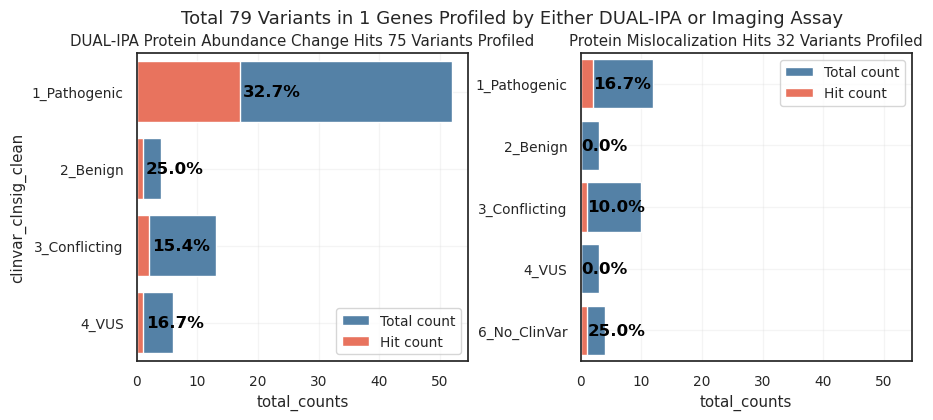

In [60]:
img_metric_df = agxt_gene_info.with_columns(
    # (pl.col("dualipa_abund_change")==1).alias("dualipa_abund_change"),
    (pl.col("Altered_95th_perc_any_batches_GFP")==1).alias("img_prot_hits_5perc")
)

img_clinvar_clean_all = img_metric_df.unique("gene_allele").filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS","5_Others","6_No_ClinVar"]),
    pl.col("zscore_log2").is_not_null()
).group_by(
    ["clinvar_clnsig_clean"]
).len().rename(
    {"len": "total_counts"}
)
img_clinvar_clean_hits_prot = img_metric_df.unique("gene_allele").filter(
    (pl.col("dualipa_abund_change")) & pl.col("zscore_log2").is_not_null()
).group_by(
    ["clinvar_clnsig_clean"]
).len().rename(
    {"len": "hit_counts"}
)
img_hits_prot = img_clinvar_clean_all.join(
    img_clinvar_clean_hits_prot,
    on=["clinvar_clnsig_clean"],
    how="left"
).fill_null(0).with_columns(
    (pl.col("hit_counts") / pl.col("total_counts") * 100).alias("hit_perc")
)
img_hits_prot.sort("clinvar_clnsig_clean")

fig, axes = plt.subplots(1,2,figsize=(10,4))
plot_df = img_hits_prot.sort("clinvar_clnsig_clean").to_pandas()
sns.barplot(plot_df, y="clinvar_clnsig_clean",
            x="total_counts", color="steelblue",
            label="Total count", ax=axes[0])
sns.barplot(plot_df, y="clinvar_clnsig_clean",
                 x="hit_counts", color="tomato",
                 label="Hit count", ax=axes[0])
axes[0].set_title(f"DUAL-IPA Protein Abundance Change Hits {img_clinvar_clean_all['total_counts'].sum()} Variants Profiled")
# Add percentage annotations
for i, row in plot_df.iterrows():
    # Position the text at the end of the red (hit_counts) bar
    axes[0].text(row['hit_counts'] + max(plot_df['total_counts']) * 0.01,  # slight offset from bar end
            i,  # y position (bar index)
            f"{row['hit_perc']:.1f}%",  # percentage text
            va='center',  # vertical alignment
            ha='left',   # horizontal alignment
            fontweight='bold',
           fontsize=12,
           color="black")
axes[0].grid(alpha=.2)

img_clinvar_clean_all = img_metric_df.unique("gene_allele").filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS","5_Others","6_No_ClinVar"]),
    pl.col("AUROC_Mean_GFP").is_not_null()
).group_by(
    ["clinvar_clnsig_clean"]
).len().rename(
    {"len": "total_counts"}
)
img_clinvar_clean_hits_all = img_metric_df.unique("gene_allele").filter(
    (pl.col("img_prot_hits_5perc")) & pl.col("AUROC_Mean_GFP").is_not_null()
).group_by(
    ["clinvar_clnsig_clean"]
).len().rename(
    {"len": "hit_counts"}
)
img_hits_all = img_clinvar_clean_all.join(
    img_clinvar_clean_hits_all,
    on=["clinvar_clnsig_clean"],
    how="left"
).fill_null(0).with_columns(
    (pl.col("hit_counts") / pl.col("total_counts") * 100).alias("hit_perc")
)
plot_df = img_hits_all.sort("clinvar_clnsig_clean").to_pandas()
sns.barplot(plot_df, y="clinvar_clnsig_clean",
            x="total_counts", color="steelblue",
            label="Total count", ax=axes[1])
sns.barplot(plot_df, y="clinvar_clnsig_clean",
                 x="hit_counts", color="tomato",
                 label="Hit count", ax=axes[1])
axes[1].set_title(f"Protein Mislocalization Hits {img_clinvar_clean_all['total_counts'].sum()} Variants Profiled")
axes[1].set_xlim(axes[0].get_xlim())
# Add percentage annotations
for i, row in plot_df.iterrows():
    # Position the text at the end of the red (hit_counts) bar
    axes[1].text(row['hit_counts'] + max(plot_df['total_counts']) * 0.01,  # slight offset from bar end
            i,  # y position (bar index)
            f"{row['hit_perc']:.1f}%",  # percentage text
            va='center',  # vertical alignment
            ha='left',   # horizontal alignment
            fontweight='bold',
           fontsize=12,
           color="black")
axes[1].grid(alpha=.2)
axes[1].set_ylabel("")
plt.suptitle(f"Total {img_metric_df.shape[0]} Variants in {img_metric_df.unique('symbol').shape[0]} Genes Profiled by Either DUAL-IPA or Imaging Assay", y=.99)
plt.subplots_adjust(wspace=.34)
plt.show()

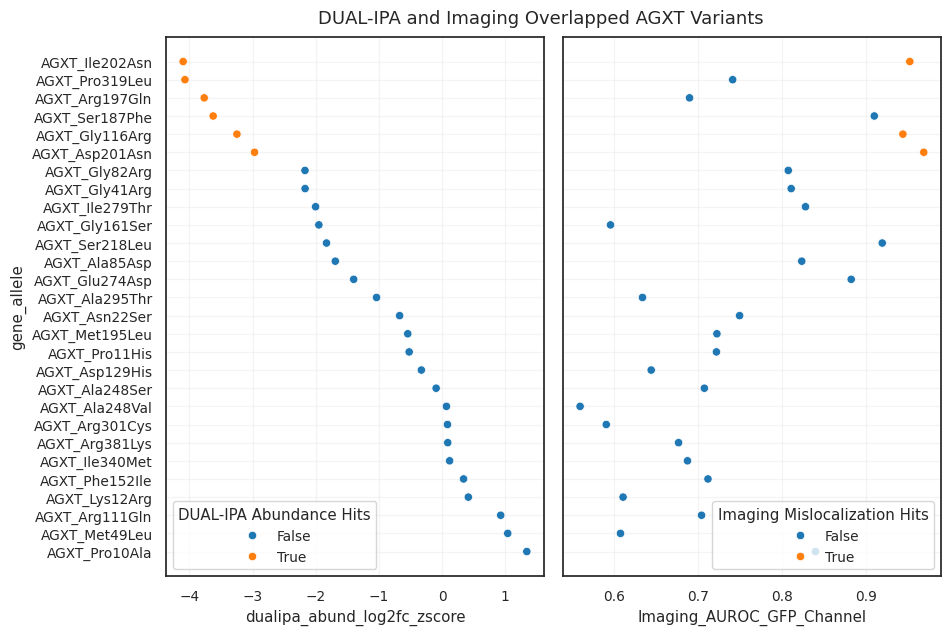

In [126]:
agxt_gene_info_overlapped = agxt_gene_info.filter(
    pl.col("Imaging_AUROC_GFP_Channel").is_not_null(),
    pl.col("dualipa_abund_log2fc_zscore").is_not_null()
).with_columns(
    (pl.col("Imaging_Altered_GFP_Channel")==1).alias("Imaging_Altered_GFP_Channel")
).sort(
    ["dualipa_abund_log2fc_zscore", "Imaging_AUROC_GFP_Channel"]
)

agxt_gene_info_overlapped
# .join(
#     agxt_gene_info.filter(
#         pl.col("AUROC_Mean_GFP").is_not_null(),
#         pl.col("zscore_log2").is_not_null()
#     ).select(
#         ["gene_allele", "dualipa_abund_change", "Altered_95th_perc_any_batches_GFP"]
#     ).rename(
#         {
#             "dualipa_abund_change": "Abundance_Changed",
#             "Altered_95th_perc_any_batches_GFP": "Mislocalized"
#         }
#     ).unpivot(
#             index="gene_allele",
#     ),
#     on="gene_allele"
# )

# agxt_gene_info_overlapped

fig, axes = plt.subplots(1, 2, figsize=(10, 7), sharey=True)
sns.scatterplot(
    agxt_gene_info_overlapped,
    y="gene_allele",
    x="dualipa_abund_log2fc_zscore",
    # hue="Score_Type",
    hue="dualipa_abund_change",
    ax=axes[0]
)
sns.scatterplot(
    agxt_gene_info_overlapped,
    y="gene_allele",
    x="Imaging_AUROC_GFP_Channel",
    # hue="Score_Type",
    hue="Imaging_Altered_GFP_Channel",
    ax=axes[1]
)
axes[0].grid(alpha=.2)
axes[1].grid(alpha=.2)
axes[0].legend(loc="lower left", title="DUAL-IPA Abundance Hits")
axes[1].legend(loc="lower right", title="Imaging Mislocalization Hits")
plt.suptitle("DUAL-IPA and Imaging Overlapped AGXT Variants", y=.92)
plt.subplots_adjust(wspace=0.05)

(-0.9, 32.1)

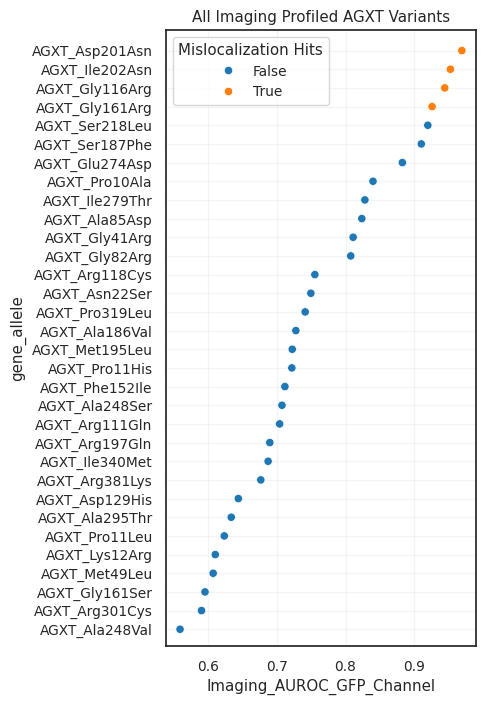

In [137]:
agxt_gene_info_overlapped = agxt_gene_info.filter(
    pl.col("Imaging_AUROC_GFP_Channel").is_not_null() 
    # & ~pl.col("dualipa_abund_log2fc_zscore").is_not_null()
).with_columns(
    (pl.col("Imaging_Altered_GFP_Channel")==1).alias("Imaging_Altered_GFP_Channel")
).sort(
    ["Imaging_AUROC_GFP_Channel"]
)

fig, axes = plt.subplots(1, 1, figsize=(4, 8), sharey=True)
sns.scatterplot(
    agxt_gene_info_overlapped,
    y="gene_allele",
    x="Imaging_AUROC_GFP_Channel",
    # hue="Score_Type",
    hue="Imaging_Altered_GFP_Channel",
    ax=axes
)
axes.grid(alpha=.2)
axes.legend(loc="upper left", title="Mislocalization Hits")
axes.set_title("All Imaging Profiled AGXT Variants")
axes.set_ylim(-.9, agxt_gene_info_overlapped.shape[0]+.1)
# plt.subplots_adjust(wspace=0.05)

(-0.9, 75.1)

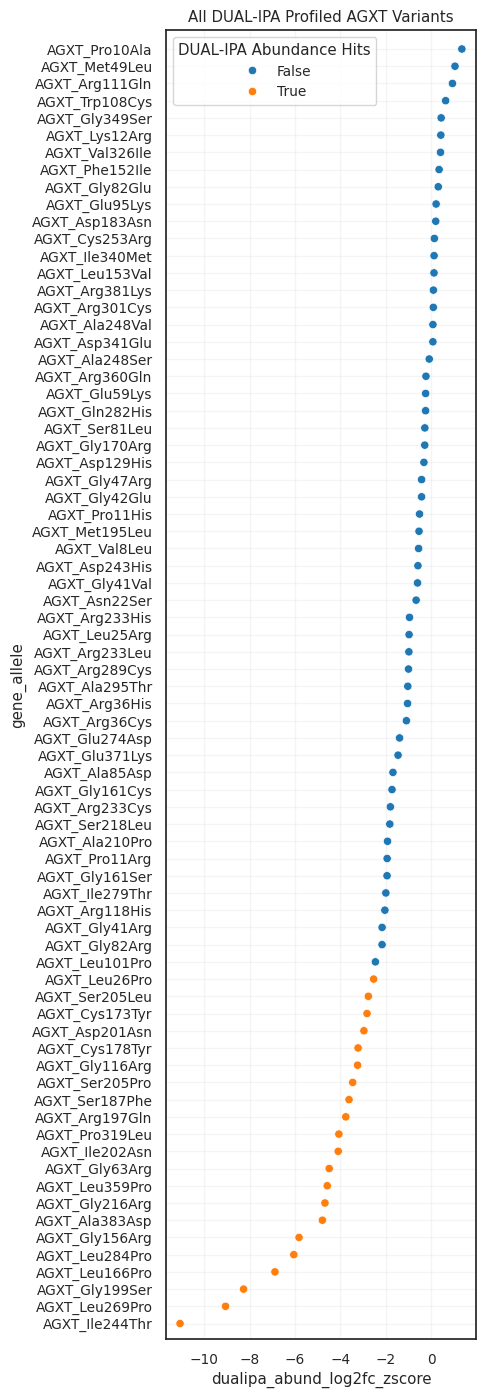

In [139]:
agxt_gene_info_overlapped = agxt_gene_info.filter(
    # ~pl.col("Imaging_AUROC_GFP_Channel").is_not_null() 
    pl.col("dualipa_abund_log2fc_zscore").is_not_null()
).sort(
    ["dualipa_abund_log2fc_zscore"]
)

fig, axes = plt.subplots(1, 1, figsize=(4, 17), sharey=True)
sns.scatterplot(
    agxt_gene_info_overlapped,
    y="gene_allele",
    x="dualipa_abund_log2fc_zscore",
    # hue="Score_Type",
    hue="dualipa_abund_change",
    ax=axes
)
axes.grid(alpha=.2)
axes.legend(loc="upper left", title="DUAL-IPA Abundance Hits")
axes.set_title("All DUAL-IPA Profiled AGXT Variants")
axes.set_ylim(-.9, agxt_gene_info_overlapped.shape[0]+.1)